In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

from sklearn.metrics import classification_report
# from tqdm.auto import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
from torchvision.models import vgg16, VGG16_Weights

vggnet = models.vgg16(weights = VGG16_Weights.DEFAULT)

In [3]:
from torchvision.models import googlenet, GoogLeNet_Weights

googlenet = models.googlenet(weights=GoogLeNet_Weights.DEFAULT)

In [4]:

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    )
])

train_dataset = ImageFolder(
    root = "DATASETS/IMAGE_CLASSIFICATION/team_10/team_10/train",
    transform = transform
)

test_dataset = ImageFolder(
    root = "DATASETS/IMAGE_CLASSIFICATION/team_10/team_10/test",
    transform = transform
)



In [ ]:
batch_size = 32

"""
shuffle is False because we will create features of image from deep CNN and that does not need shuffling of data
"""

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

num_classes = len(train_dataset.classes)
print(f"Number of classes: {num_classes}")

Number of classes: 5


In [ ]:
"""
Removing classifier layer

model.eval() - deactivates dropout layers, and freezes normalization layers
"""

vggnet.classifier = nn.Identity()
vggnet = vggnet.to(device)
_ = vggnet.eval()

googlenet.fc = nn.Identity()
googlenet = googlenet.to(device)
_ = googlenet.eval()

In [ ]:
def extract_features(model, dataloader):
    features_list = []
    labels_list = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)

            features = model(images)
            
            features_list.append(features.cpu())
            labels_list.append(labels)
            
    return torch.cat(features_list), torch.cat(labels_list)

print("Extracting VGGNet features...")
vgg_train_features, vgg_train_labels = extract_features(vggnet, train_loader)
vgg_test_features, vgg_test_labels = extract_features(vggnet, test_loader)
print(f"VGG Train feature shape: {vgg_train_features.shape}")

print("Extracting GoogLeNet features...")
google_train_features, google_train_labels = extract_features(googlenet, train_loader)
google_test_features, google_test_labels = extract_features(googlenet, test_loader)
print(f"GoogLeNet Train feature shape: {google_train_features.shape}")

Extracting VGGNet features...
VGG Train feature shape: torch.Size([3500, 25088])
Extracting GoogLeNet features...
GoogLeNet Train feature shape: torch.Size([3500, 1024])


In [8]:
class MLFFNN(nn.Module):
    def __init__(self, input, hidden1, hidden2, output):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input, hidden1),
            nn.ReLU(),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),

            nn.Linear(hidden2, output)
        )
    
    def forward(self, x):
        return self.model(x)
    

In [9]:
class Config:
    VGG_FEATURE_SIZE = vgg_train_features.shape[1]
    GOOGLE_FEATURE_SIZE = google_train_features.shape[1]
    
    HIDDEN_LAYER_1 = [128, 256, 512, 1024]
    HIDDEN_LAYER_2 = [64, 128, 256, 512]

    NUM_CLASSES = num_classes

In [10]:
config = Config

In [11]:
torch.manual_seed(42)
vgg_classifier = MLFFNN(
    input = config.VGG_FEATURE_SIZE,
    hidden1 = config.HIDDEN_LAYER_1[2],
    hidden2 = config.HIDDEN_LAYER_2[2],
    output = config.NUM_CLASSES
)

torch.manual_seed(42)
google_classifier = MLFFNN(
    input = config.GOOGLE_FEATURE_SIZE,
    hidden1 = config.HIDDEN_LAYER_1[2],
    hidden2 = config.HIDDEN_LAYER_2[2],
    output = config.NUM_CLASSES
)

In [ ]:
results = []

def train_and_evaluate_mlffnn(train_features, train_labels, test_features, test_labels, title, h1, h2):

    input_dim = train_features.shape[1]
    model = MLFFNN(input_dim, h1, h2, config.NUM_CLASSES).to(device)

    train_loader = DataLoader(TensorDataset(train_features, train_labels), batch_size=32, shuffle=True)
    test_loader = DataLoader(TensorDataset(test_features, test_labels), batch_size=32, shuffle=False)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr = 0.001)

    print(f"\n--- Training MLFFNN on {title} Features ---")

    
    epochs = 10
    
    # Training Loop
    model.train()

    for epoch in range(epochs):
        # running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            # running_loss += loss.item()
            
        # print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_feat_loader):.4f}")
        
    # Evaluation
    model.eval()

    def get_accuracy(loader):
        correct_count, total_count = 0, 0
        with torch.no_grad():
            for inputs, labels in loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total_count += labels.size(0)
                correct_count += (predicted == labels).sum().item()
        return 100 * correct_count / total_count
    
    train_accuracy = get_accuracy(train_loader)

    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
    
    test_correct = (np.array(all_preds) == np.array(all_targets)).sum()
    test_accuracy = 100 * test_correct / len(all_targets)
    # print(f"Accuracy for MLFFNN on {title} features: {accuracy:.2f}%")

    report_string = classification_report(all_targets, all_preds, target_names=train_dataset.classes, output_dict=False)
    report_dict = classification_report(all_targets, all_preds, target_names=train_dataset.classes, output_dict=True) 
    results.append({
        'Backbone' : title,
        'H1' : h1,
        'H2' : h2,
        'Train_Accuracy' : train_accuracy,
        'Test_Accuracy' : test_accuracy,
        'Report_dict' : report_dict,
        'Report' : report_string,
        'state_dict': model.state_dict(),
        'input_dim': input_dim
    })

    print(f"\n{title} (H1:{h1}, H2:{h2}) ----> Train Acc: {train_accuracy:.2f}% | Test Acc: {test_accuracy:.2f}%\n\n")


for h1 in config.HIDDEN_LAYER_1:
    for h2 in config.HIDDEN_LAYER_2:
        if h2 < h1:
            train_and_evaluate_mlffnn(vgg_train_features, vgg_train_labels, vgg_test_features, vgg_test_labels, "VGG16", h1, h2)
            train_and_evaluate_mlffnn(google_train_features, google_train_labels, google_test_features, google_test_labels, "GoogLeNet", h1, h2)


--- Training MLFFNN on VGG16 Features ---

VGG16 (H1:128, H2:64) ----> Train Acc: 100.00% | Test Acc: 97.43%



--- Training MLFFNN on GoogLeNet Features ---

GoogLeNet (H1:128, H2:64) ----> Train Acc: 99.94% | Test Acc: 96.29%



--- Training MLFFNN on VGG16 Features ---

VGG16 (H1:256, H2:64) ----> Train Acc: 100.00% | Test Acc: 96.29%



--- Training MLFFNN on GoogLeNet Features ---

GoogLeNet (H1:256, H2:64) ----> Train Acc: 98.51% | Test Acc: 95.43%



--- Training MLFFNN on VGG16 Features ---

VGG16 (H1:256, H2:128) ----> Train Acc: 100.00% | Test Acc: 97.14%



--- Training MLFFNN on GoogLeNet Features ---

GoogLeNet (H1:256, H2:128) ----> Train Acc: 99.97% | Test Acc: 96.29%



--- Training MLFFNN on VGG16 Features ---

VGG16 (H1:512, H2:64) ----> Train Acc: 99.89% | Test Acc: 96.57%



--- Training MLFFNN on GoogLeNet Features ---

GoogLeNet (H1:512, H2:64) ----> Train Acc: 96.74% | Test Acc: 94.14%



--- Training MLFFNN on VGG16 Features ---

VGG16 (H1:512, H2:128) ----> Tr

In [ ]:
results_df = pd.DataFrame(results)

# finding best vgg model
vgg_df = results_df[results_df['Backbone'] == 'VGG16']
best_vgg = vgg_df.loc[vgg_df['Test_Accuracy'].idxmax()]

# finding best googlenet model
google_df = results_df[results_df['Backbone'] == 'GoogLeNet']
best_google = google_df.loc[google_df['Test_Accuracy'].idxmax()]

for best_model in [best_vgg, best_google]:
    print("\n" + "="*30)
    print(f"BEST MODEL: {best_model['Backbone']}")
    print(f"Configuration: H1={best_model['H1']}, H2={best_model['H2']}")
    print(f"Train Acc: {best_model['Train_Accuracy']:.2f}%")
    print(f"Test Acc: {best_model['Test_Accuracy']:.2f}%")
    print("="*30)
    
    print(f"\nFinal Classification Report for {best_model['Backbone']}:")
    print(best_model['Report'])


BEST MODEL: VGG16
Configuration: H1=128, H2=64
Train Acc: 100.00%
Test Acc: 97.43%

Final Classification Report for VGG16:
              precision    recall  f1-score   support

   n01560419       0.95      0.96      0.95       140
   n01582220       0.96      0.98      0.97       140
   n01592084       0.96      0.94      0.95       140
   n01753488       1.00      0.99      1.00       140
   n01773157       1.00      1.00      1.00       140

    accuracy                           0.97       700
   macro avg       0.97      0.97      0.97       700
weighted avg       0.97      0.97      0.97       700


BEST MODEL: GoogLeNet
Configuration: H1=1024, H2=512
Train Acc: 99.77%
Test Acc: 96.86%

Final Classification Report for GoogLeNet:
              precision    recall  f1-score   support

   n01560419       0.97      0.95      0.96       140
   n01582220       0.99      0.96      0.97       140
   n01592084       0.95      0.94      0.95       140
   n01753488       0.96      0.99    

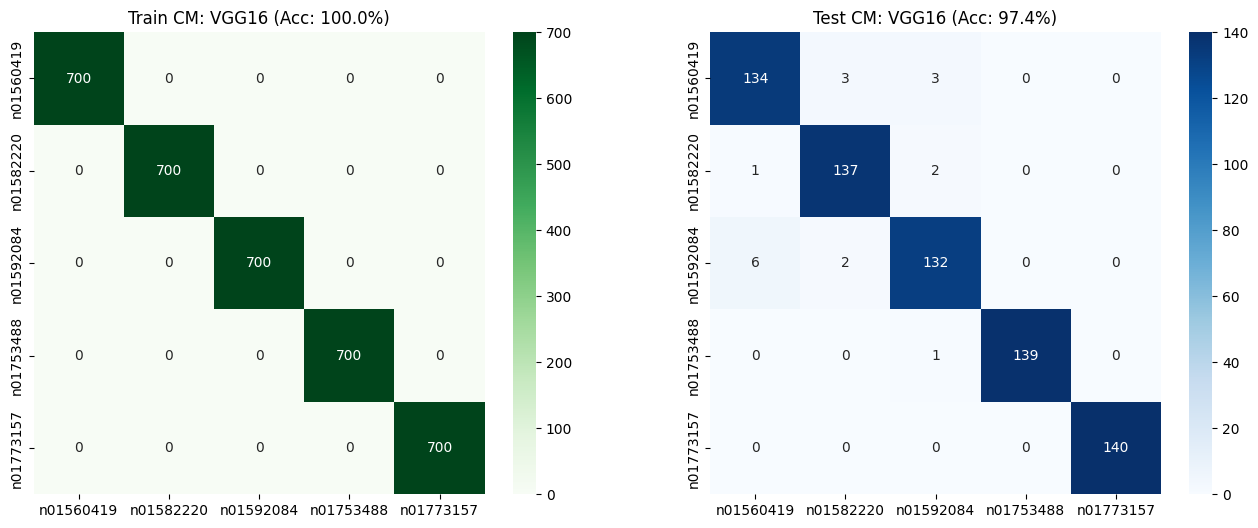

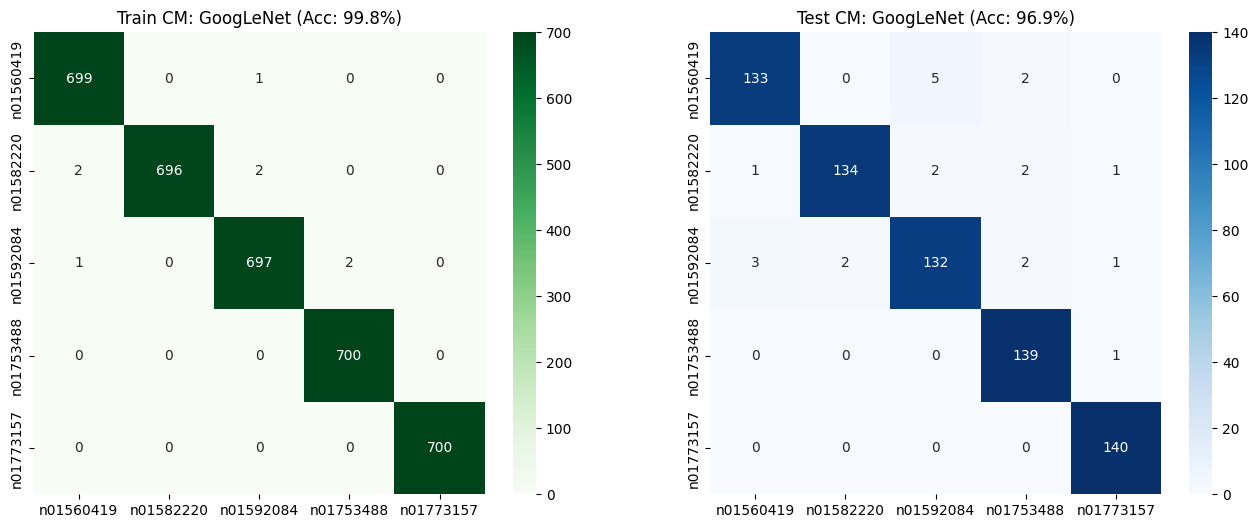

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

for best_row in [best_vgg, best_google]:
    
    model = MLFFNN(best_row['input_dim'], best_row['H1'], best_row['H2'], config.NUM_CLASSES).to(device)
    model.load_state_dict(best_row['state_dict'])
    model.eval()

    if best_row['Backbone'] == "VGG16":
        train_f, train_l, test_f, test_l = vgg_train_features, vgg_train_labels, vgg_test_features, vgg_test_labels
    else:
        train_f, train_l, test_f, test_l = google_train_features, google_train_labels, google_test_features, google_test_labels

    plt.figure(figsize=(16, 6))

    for i, (f, l, title, cmap) in enumerate([(train_f, train_l, "Train", "Greens"), (test_f, test_l, "Test", "Blues")], 1):
        with torch.no_grad():
            outputs = model(f.to(device))
            _, preds = torch.max(outputs, 1)
            y_pred, y_true = preds.cpu().numpy(), l.numpy()
        
        plt.subplot(1, 2, i)
        sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap=cmap,
                    xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
        plt.title(f"{title} CM: {best_row['Backbone']} (Acc: {best_row[title+'_Accuracy']:.1f}%)")

    plt.show()